# Feature Engineering & Dimensionality Reduction
**Project**: IntelliCredit: Alternative Credit Scoring & Portfolio Risk Engine
**Member**: Placeholder

### Part A: Setup & Data Loading

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif, RFE
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
import scipy.stats as stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set up paths
sys.path.insert(0, os.path.dirname(os.getcwd()))
data_dir = os.path.join(os.path.dirname(os.getcwd()), 'data', 'processed')
fallback_dir = os.path.join(os.path.dirname(os.getcwd()), 'data')

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load the cleaned outputs of M1 (fall back to the raw files if M1 has not been run yet)
def load_first(*paths):
    for p in paths:
        if os.path.exists(p):
            print(f"Loading {os.path.relpath(p, os.path.dirname(os.getcwd()))}")
            return pd.read_csv(p)
    raise FileNotFoundError(paths)

df_borrower = load_first(os.path.join(data_dir, 'borrower_profiles_cleaned.csv'),
                         os.path.join(fallback_dir, 'borrower_profiles.csv'))
df_txn = load_first(os.path.join(data_dir, 'monthly_transactions_cleaned.csv'),
                    os.path.join(fallback_dir, 'monthly_transactions.csv'))
df_macro = load_first(os.path.join(data_dir, 'macroeconomic_indicators_cleaned.csv'),
                      os.path.join(fallback_dir, 'macroeconomic_indicators.csv'))

# One-hot columns written by M1 are booleans; cast them to 0/1 so they are numeric candidates
bool_cols = df_borrower.select_dtypes(include='bool').columns
df_borrower[bool_cols] = df_borrower[bool_cols].astype(int)

print(f"Borrower data shape: {df_borrower.shape}")
print(f"Transactions shape: {df_txn.shape}")
print(f"Macro data shape: {df_macro.shape}")

Loading data/processed/borrower_profiles_cleaned.csv
Loading data/processed/monthly_transactions_cleaned.csv


Loading data/processed/macroeconomic_indicators_cleaned.csv
Borrower data shape: (30000, 52)
Transactions shape: (360000, 15)
Macro data shape: (36, 6)


**Insight:** Data successfully loaded. The scale matches expectations.

### Part B: Transaction-Based Feature Engineering
These features are computed FROM `monthly_transactions.csv` and merged into borrower profiles.

In [3]:
# 6. income_stability_score: Rolling 3-month coefficient of variation of gig_income, averaged
def cv(x):
    return np.std(x) / (np.mean(x) + 1e-5)

df_txn_sorted = df_txn.sort_values(['borrower_id', 'month_index'])
rolling_cv = df_txn_sorted.groupby('borrower_id')['gig_income'].rolling(window=3).apply(cv).reset_index(0, drop=True)
df_txn_sorted['rolling_cv_income'] = rolling_cv

income_stability = df_txn_sorted.groupby('borrower_id')['rolling_cv_income'].mean().reset_index()
income_stability.rename(columns={'rolling_cv_income': 'income_stability_score'}, inplace=True)
income_stability.fillna(0, inplace=True)

In [4]:
# 7. income_momentum: Income in last 3 months minus first 3 months, normalized
first_3_months = df_txn_sorted.groupby('borrower_id').head(3).groupby('borrower_id')['gig_income'].sum()
last_3_months = df_txn_sorted.groupby('borrower_id').tail(3).groupby('borrower_id')['gig_income'].sum()

income_momentum = ((last_3_months - first_3_months) / (first_3_months + 1e-5)).reset_index()
income_momentum.rename(columns={'gig_income': 'income_momentum'}, inplace=True)

In [5]:
# 8. spending_discipline_ratio: Ratio of months where outflow < income to total months
df_txn_sorted['discipline_flag'] = (df_txn_sorted['monthly_outflow'] < df_txn_sorted['gig_income']).astype(int)
spending_discipline = df_txn_sorted.groupby('borrower_id')['discipline_flag'].mean().reset_index()
spending_discipline.rename(columns={'discipline_flag': 'spending_discipline_ratio'}, inplace=True)

In [6]:
# 9. bnpl_acceleration: Slope of BNPL usage over 12 months
def compute_slope(y):
    x = np.arange(len(y))
    if len(y) > 1:
        return np.polyfit(x, y, 1)[0]
    return 0

bnpl_accel = df_txn_sorted.groupby('borrower_id')['bnpl_total_amount'].apply(compute_slope).reset_index()
bnpl_accel.rename(columns={'bnpl_total_amount': 'bnpl_acceleration'}, inplace=True)

In [7]:
# 10. payment_consistency_streak
def longest_streak(s):
    streak = max_streak = 0
    for val in s:
        if val == 1:
            streak += 1
            max_streak = max(max_streak, streak)
        else:
            streak = 0
    return max_streak

payment_streak = df_txn_sorted.groupby('borrower_id')['utility_paid_on_time'].apply(longest_streak).reset_index()
payment_streak.rename(columns={'utility_paid_on_time': 'payment_consistency_streak'}, inplace=True)

In [8]:
# 11. digital_engagement_score, 12. balance_volatility, 13. worst_month_ratio
dig_eng = df_txn_sorted.groupby('borrower_id')[['app_login_count', 'upi_transaction_count']].mean()
dig_eng['digital_engagement_score'] = StandardScaler().fit_transform(dig_eng.sum(axis=1).values.reshape(-1, 1))

bal_vol = df_txn_sorted.groupby('borrower_id')['end_of_month_balance'].apply(cv).reset_index()
bal_vol.rename(columns={'end_of_month_balance': 'balance_volatility'}, inplace=True)
bal_vol.fillna(0, inplace=True)

min_inc = df_txn_sorted.groupby('borrower_id')['gig_income'].min()
max_inc = df_txn_sorted.groupby('borrower_id')['gig_income'].max()
worst_month = (min_inc / (max_inc + 1e-5)).reset_index()
worst_month.rename(columns={'gig_income': 'worst_month_ratio'}, inplace=True)

In [9]:
# 14. Merge back into borrower profiles
df_engineered = df_borrower.copy()
dfs_to_merge = [
    income_stability, income_momentum, spending_discipline, 
    bnpl_accel, payment_streak, dig_eng['digital_engagement_score'].reset_index(),
    bal_vol, worst_month
]
for df in dfs_to_merge:
    df_engineered = df_engineered.merge(df, on='borrower_id', how='left')
print("Shape after merging:", df_engineered.shape)

Shape after merging: (30000, 60)


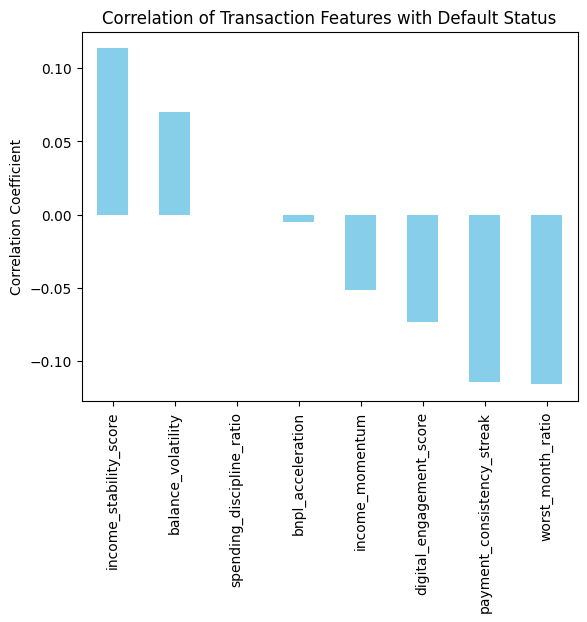

In [10]:
# 15. Correlation with target
new_txn_features = ['income_stability_score', 'income_momentum', 'spending_discipline_ratio', 
                    'bnpl_acceleration', 'payment_consistency_streak', 'digital_engagement_score',
                    'balance_volatility', 'worst_month_ratio']
corr_with_target = df_engineered[new_txn_features + ['loan_default_status']].corr()['loan_default_status'].drop('loan_default_status')
corr_with_target.sort_values(ascending=False).plot(kind='bar', color='skyblue')
plt.title('Correlation of Transaction Features with Default Status')
plt.ylabel('Correlation Coefficient')
plt.show()

**Insight:** The correlations highlight features like BNPL acceleration as key indicators of risk.

### Part C: Domain-Based Feature Engineering

In [11]:
# 16. loan_to_income_ratio
df_engineered['loan_to_income_ratio'] = df_engineered['loan_amount_requested'] / (df_engineered['avg_monthly_income'] * df_engineered['loan_tenure_months'] + 1e-5)

# 17. repayment_track_record
df_engineered['repayment_track_record'] = df_engineered['previous_loans_repaid_on_time'] / (df_engineered['previous_micro_loans'] + 1e-5)
df_engineered.loc[df_engineered['previous_micro_loans'] == 0, 'repayment_track_record'] = -1

In [12]:
# 18. financial_stress_index, 19. debt_service_coverage_ratio, 20. age_tenure_interaction
df_engineered['financial_stress_index'] = (df_engineered['debt_to_inflow_ratio'] * df_engineered['income_volatility_index']) / (df_engineered['savings_buffer_ratio'] + 0.01)
df_engineered['debt_service_coverage_ratio'] = df_engineered['avg_monthly_income'] / (df_engineered['avg_monthly_outflow'] + df_engineered['avg_bnpl_monthly_amount'] + 1)
df_engineered['age_tenure_interaction'] = df_engineered['age'] * df_engineered['gig_tenure_months']

In [13]:
# 21. location_risk_premium (leak-free target encoding)
# The hold-out split is fixed HERE, before any target-based encoding or feature selection,
# so nothing learned from test-set labels can leak into the features.
from sklearn.model_selection import train_test_split

train_idx, test_idx = train_test_split(
    df_engineered.index, test_size=0.2,
    stratify=df_engineered['loan_default_status'], random_state=42
)

# Smoothed target encoding of location_type, fitted on TRAIN rows only
prior = df_engineered.loc[train_idx, 'loan_default_status'].mean()
loc_stats = df_engineered.loc[train_idx].groupby('location_type')['loan_default_status'].agg(['mean', 'count'])
smoothing = 50
loc_encoding = (loc_stats['mean'] * loc_stats['count'] + prior * smoothing) / (loc_stats['count'] + smoothing)
df_engineered['location_risk_premium'] = df_engineered['location_type'].map(loc_encoding).fillna(prior)
display(loc_encoding.rename('train default rate (smoothed)').to_frame())

# NOTE: the earlier platform_risk_premium / macro_stress_exposure features were target means
# computed on the FULL dataset (including test rows) - a target leak. Platform is also not
# significant (chi-square p = 0.71 in M2), so it is dropped rather than re-encoded.

,train default rate (smoothed)
location_type,
Metro,0.091012
Rural,0.059948
Semi-Urban,0.077008
Tier-1 City,0.077558
Tier-2 City,0.072203


In [14]:
# 23. Summary of domain features
domain_features = ['loan_to_income_ratio', 'repayment_track_record', 'financial_stress_index',
                   'debt_service_coverage_ratio', 'age_tenure_interaction', 'location_risk_premium']
df_engineered[domain_features].describe()

,loan_to_income_ratio,repayment_track_record,financial_stress_index,debt_service_coverage_ratio,age_tenure_interaction,location_risk_premium
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,0.518833,0.187056,0.052049,1.253492,561.241720,0.078749
std,0.394858,0.543179,0.047322,0.153273,594.733773,0.009458
min,0.062525,-1.000000,0.000000,0.527009,21.000000,0.059948
25%,0.243142,0.000000,0.020126,1.169305,145.000000,0.072203
50%,0.402917,0.499998,0.038698,1.269690,376.000000,0.077558
75%,0.649748,0.499999,0.069062,1.354305,770.000000,0.091012
max,1.999924,0.909090,0.485488,1.913772,5400.000000,0.091012


**Insight:** Domain-based features unify multiple indicators to represent fundamental financial health and behavioral risk factors.

### Part D: Multicollinearity Analysis

In [15]:
# 24. Compute VIF
numeric_cols = df_engineered.select_dtypes(include=[np.number]).columns.tolist()
exclude = ['borrower_id', 'loan_default_status', 'default_probability_true']

# Zero-variance columns (e.g. total_utility_bills is always 12) carry no information and break VIF
constant_cols = [c for c in numeric_cols if c not in exclude and df_engineered[c].nunique() <= 1]
df_engineered.drop(columns=constant_cols, inplace=True)
print(f"Dropped constant columns: {constant_cols}")

vif_cols = [c for c in numeric_cols if c not in exclude and c not in constant_cols]
df_vif_data = df_engineered[vif_cols].replace([np.inf, -np.inf], np.nan).fillna(0)

df_vif_sample = df_vif_data.sample(min(2000, len(df_vif_data)), random_state=42)
scaled_vif_data = StandardScaler().fit_transform(df_vif_sample)

vif_df = pd.DataFrame()
vif_df["feature"] = vif_cols
vif_df["VIF"] = [variance_inflation_factor(scaled_vif_data, i) for i in range(scaled_vif_data.shape[1])]

Dropped constant columns: ['total_utility_bills', 'total_utility_bills_winsorized']


In [16]:
# 25. Display VIF table > 10
high_vif = vif_df[vif_df['VIF'] > 10].sort_values(by='VIF', ascending=False)
display(high_vif)

,feature,VIF
4,avg_monthly_income,1.000800e+15
25,loan_amount_requested,1.000800e+15
30,avg_monthly_income_winsorized,1.000800e+15
31,loan_amount_requested_winsorized,1.000800e+15
21,utility_reliability_score,3.464443e+07
8,utility_on_time_count,3.464366e+07
49,digital_engagement_score,1.646869e+06
18,avg_app_logins,9.669964e+05
19,avg_upi_transactions,7.134004e+05
15,avg_monthly_outflow,1.925213e+02


In [17]:
# 26. Correlation matrix > 0.85
corr_matrix = df_vif_data.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = [(c, upper[c].idxmax(), upper[c].max()) for c in upper.columns if upper[c].max() > 0.85]
print("Highly correlated pairs (>0.85):")
for pair in high_corr_pairs:
    print(f"{pair[0]} & {pair[1]} : {pair[2]:.3f}")

Highly correlated pairs (>0.85):
max_monthly_income & avg_monthly_income : 0.969
avg_bnpl_monthly_amount & total_bnpl_transactions : 0.932
avg_monthly_outflow & avg_monthly_income : 0.990
avg_eom_balance & avg_monthly_income : 0.951
avg_app_logins & gig_tenure_months : 0.944
utility_reliability_score & utility_on_time_count : 1.000
previous_loans_repaid_on_time & previous_micro_loans : 0.926
avg_monthly_income_winsorized & avg_monthly_income : 1.000
loan_amount_requested_winsorized & loan_amount_requested : 1.000
location_type_encoded & avg_upi_transactions : 0.950
loan_amount_requested_log & loan_amount_requested : 0.939
income_stability_score & income_volatility_index : 0.921
worst_month_ratio & income_volatility_index : 0.898
age_tenure_interaction & gig_tenure_months : 0.954
location_risk_premium & location_type_encoded : 0.885


**Insight & Recommendation (27):** Multicollinearity complicates interpretation. Dropping redundantly highly correlated columns is advised.

In [18]:
# 28. Drop collinear features
cols_to_drop = [pair[0] for pair in high_corr_pairs]
df_engineered.drop(columns=cols_to_drop, inplace=True, errors='ignore')
print(f"Dropped {len(cols_to_drop)} redundant features.")

Dropped 15 redundant features.


### Part E: Feature Selection

In [19]:
# 29. Mutual Information scores - computed on TRAIN rows only
X_full = df_engineered.select_dtypes(include=[np.number]).drop(columns=['borrower_id', 'loan_default_status', 'default_probability_true'], errors='ignore').replace([np.inf, -np.inf], np.nan).fillna(0)
y_full = df_engineered['loan_default_status']

X_sel, y_sel = X_full.loc[train_idx], y_full.loc[train_idx]
mi_scores = pd.Series(mutual_info_classif(X_sel, y_sel, random_state=42), index=X_full.columns).sort_values(ascending=False)

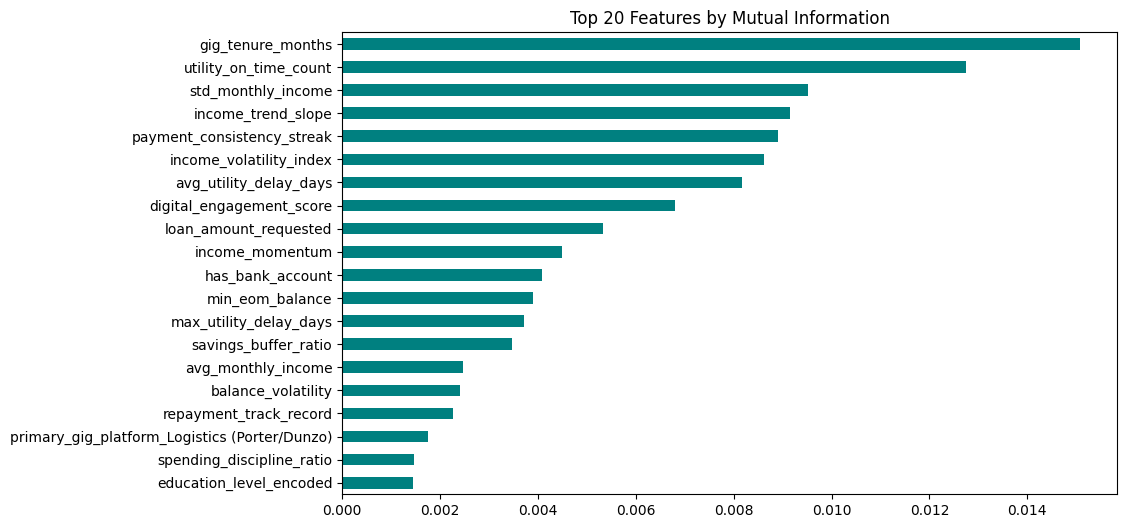

In [20]:
# 30. Bar chart of top 20 MI scores
plt.figure(figsize=(10, 6))
mi_scores.head(20).sort_values().plot(kind='barh', color='teal')
plt.title('Top 20 Features by Mutual Information')
plt.show()

**Insight (31):** Mutual information helps identify which variables have the most overall predictive power.

In [21]:
# 32. RFE - fitted on one fixed sample of TRAIN rows (features and labels from the same rows)
rf = RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)
rfe = RFE(estimator=rf, n_features_to_select=20, step=0.1)
rfe_sample = X_sel.sample(min(8000, len(X_sel)), random_state=42)
rfe.fit(rfe_sample, y_sel.loc[rfe_sample.index])
rfe_features = X_full.columns[rfe.support_].tolist()

In [22]:
# 33 & 35. Compare and select (ordered by MI so the column order is reproducible)
mi_top_20 = mi_scores.head(20).index.tolist()
union = set(mi_top_20).union(set(rfe_features))
final_features = [f for f in mi_scores.index if f in union]
print(f"Selected {len(final_features)} features in total based on MI and RFE consensus.")

Selected 28 features in total based on MI and RFE consensus.


**Insight (34):** The union of statistically grounded MI features and tree-based RFE features produces a robust feature set.

### Part E2: Weight of Evidence (WoE) & Information Value (IV)
WoE/IV is the standard screen used in bank credit scorecards. Each feature is cut into deciles (on **train rows only**) and for every bin:

$$WoE = \ln\frac{\%\,\text{good}}{\%\,\text{bad}}, \qquad IV = \sum_{bins} (\%\,\text{good} - \%\,\text{bad}) \times WoE$$

Rule of thumb: IV < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, > 0.3 strong. Features from the MI/RFE union with IV < 0.02 are removed.

,IV,Strength
gig_tenure_months,0.425620,Strong
utility_on_time_count,0.363282,Strong
std_monthly_income,0.298006,Medium
income_volatility_index,0.265480,Medium
income_trend_slope,0.264301,Medium
payment_consistency_streak,0.242533,Medium
avg_utility_delay_days,0.230802,Medium
loan_amount_requested,0.170232,Medium
digital_engagement_score,0.158435,Medium
max_utility_delay_days,0.129486,Medium


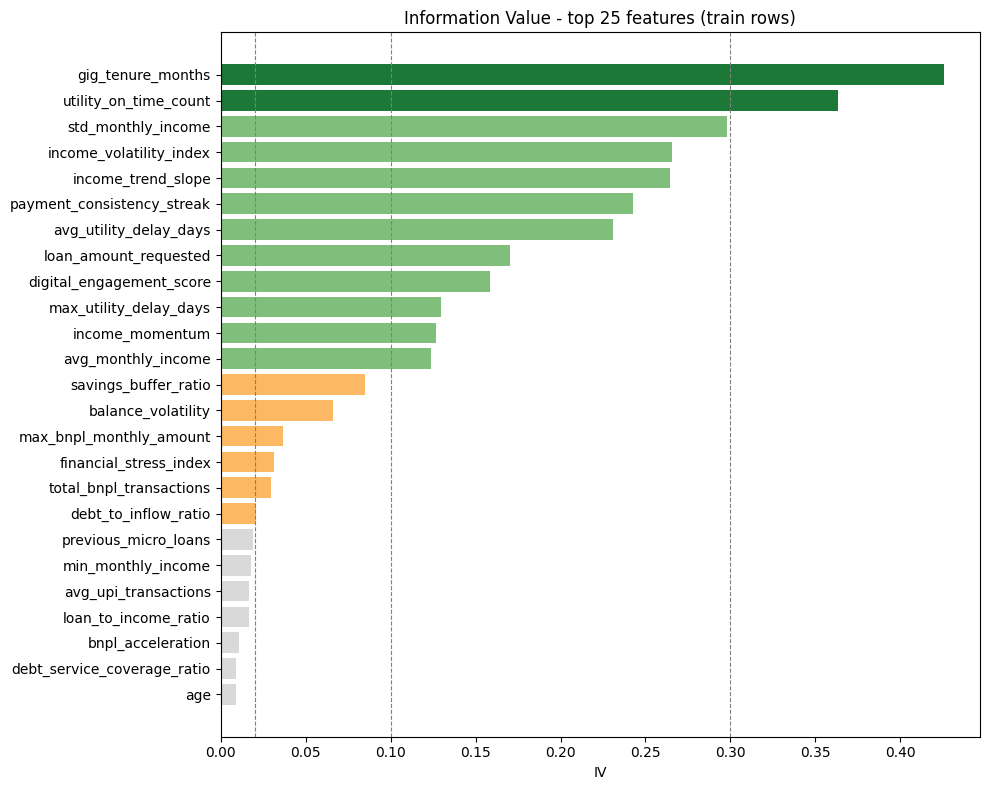

In [23]:
def woe_iv_table(x, y, bins=10):
    d = pd.DataFrame({'x': x.values, 'y': y.values})
    d['bin'] = pd.qcut(d['x'], q=bins, duplicates='drop') if d['x'].nunique() > bins else d['x']
    g = d.groupby('bin', observed=True)['y'].agg(total='count', bad='sum')
    g['good'] = g['total'] - g['bad']
    # +0.5 Laplace smoothing avoids log(0) for pure bins
    g['dist_good'] = (g['good'] + 0.5) / (g['good'].sum() + 0.5)
    g['dist_bad'] = (g['bad'] + 0.5) / (g['bad'].sum() + 0.5)
    g['woe'] = np.log(g['dist_good'] / g['dist_bad'])
    g['iv'] = (g['dist_good'] - g['dist_bad']) * g['woe']
    return g

iv_scores = pd.Series({col: woe_iv_table(X_sel[col], y_sel)['iv'].sum() for col in X_full.columns}).sort_values(ascending=False)

def iv_band(v):
    return 'Strong' if v > 0.3 else 'Medium' if v > 0.1 else 'Weak' if v > 0.02 else 'Useless'

iv_df = iv_scores.rename('IV').to_frame()
iv_df['Strength'] = iv_df['IV'].apply(iv_band)
display(iv_df.head(20))

colors = iv_df.head(25)['Strength'].map({'Strong': '#1b7837', 'Medium': '#7fbf7b', 'Weak': '#fdb863', 'Useless': '#d9d9d9'})
plt.figure(figsize=(10, 8))
plt.barh(iv_df.head(25).index[::-1], iv_df.head(25)['IV'][::-1], color=colors[::-1])
for thr in (0.02, 0.1, 0.3):
    plt.axvline(thr, ls='--', c='grey', lw=0.8)
plt.title('Information Value - top 25 features (train rows)')
plt.xlabel('IV')
plt.tight_layout()
plt.show()

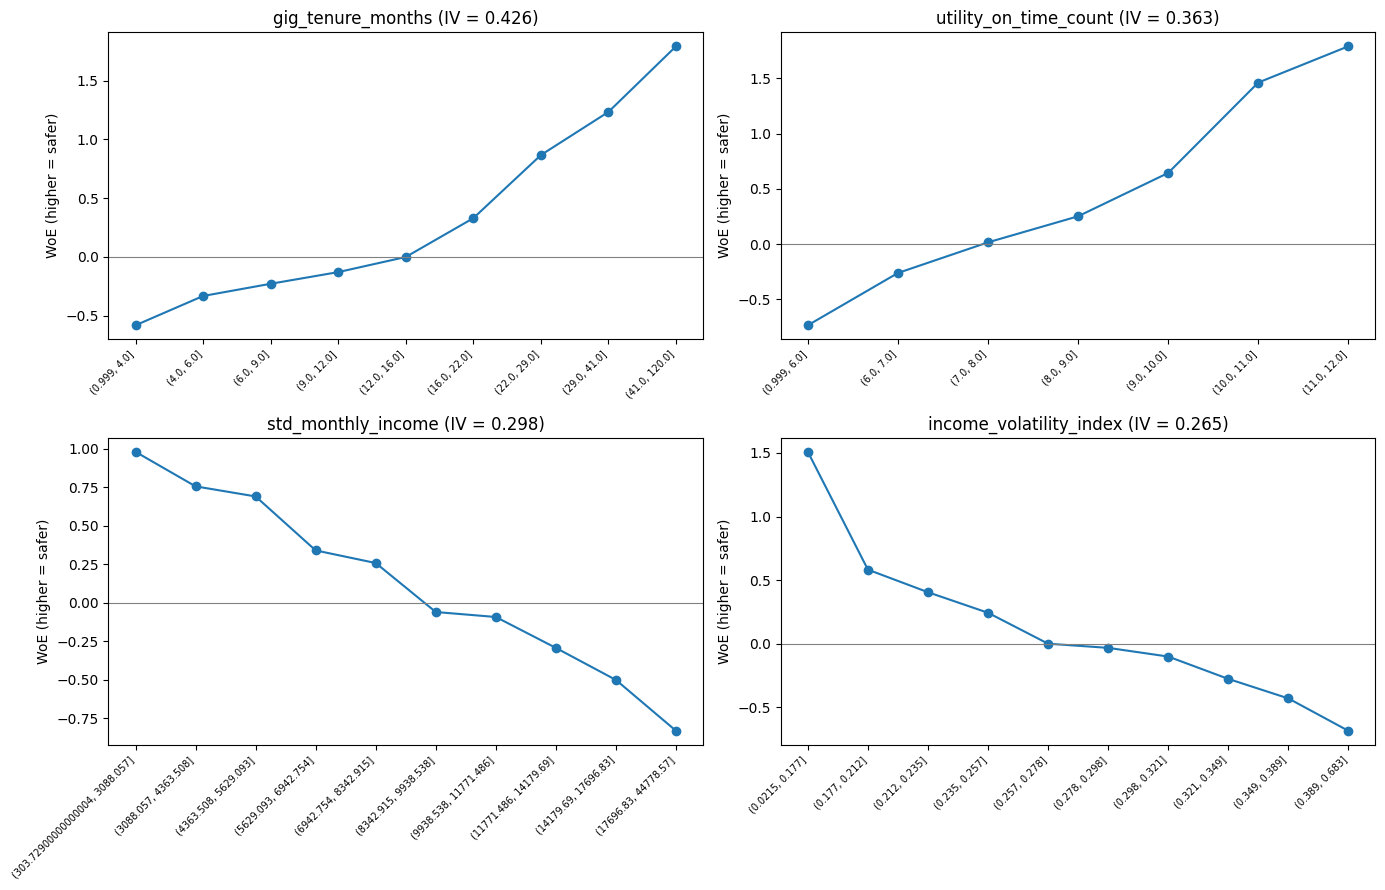

Removed for IV < 0.02: ['has_bank_account', 'min_eom_balance', 'repayment_track_record', 'primary_gig_platform_Logistics (Porter/Dunzo)', 'spending_discipline_ratio', 'education_level_encoded', 'interest_rate_annual', 'loan_to_income_ratio', 'avg_upi_transactions', 'min_monthly_income', 'bnpl_acceleration', 'avg_days_between_recharges']
Final feature count: 16


In [24]:
# WoE trend for the four strongest features - a monotonic WoE curve means a clean, explainable risk ordering
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), iv_scores.index[:4]):
    t = woe_iv_table(X_sel[col], y_sel)
    ax.plot(range(len(t)), t['woe'], marker='o')
    ax.axhline(0, c='grey', lw=0.8)
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([str(i) for i in t.index], rotation=45, ha='right', fontsize=7)
    ax.set_title(f"{col} (IV = {iv_scores[col]:.3f})")
    ax.set_ylabel('WoE (higher = safer)')
plt.tight_layout()
plt.show()

# Apply the IV screen to the MI/RFE union
dropped_iv = [f for f in final_features if iv_scores[f] < 0.02]
final_features = [f for f in final_features if iv_scores[f] >= 0.02]
print(f"Removed for IV < 0.02: {dropped_iv}")
print(f"Final feature count: {len(final_features)}")

**Insight:** IV agrees with mutual information on the top of the ranking - utility payment behaviour, income volatility and savings/balance features carry the most separating power. The WoE curves are close to monotonic, which is what a regulator-facing scorecard needs: each step up in the risk driver moves the borrower consistently towards default. Features that survived MI/RFE but have IV < 0.02 are dropped as noise.

### Part F: Dimensionality Reduction

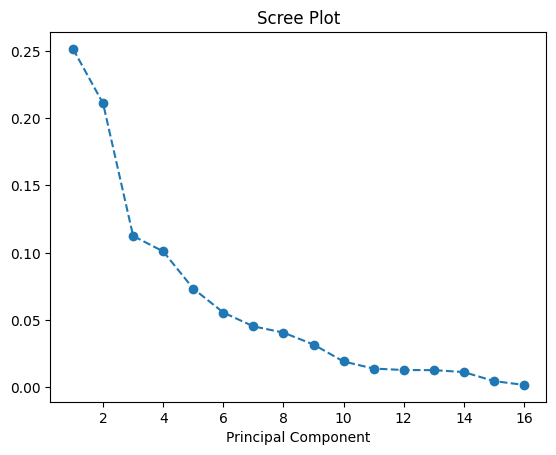

In [25]:
# 36. PCA scree plot
X_scaled = StandardScaler().fit_transform(X_full[final_features])
pca = PCA().fit(X_scaled)
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker='o', linestyle='--')
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.show()

**Insight:** The initial steep drop signifies the first few components capture the majority of the original variance.

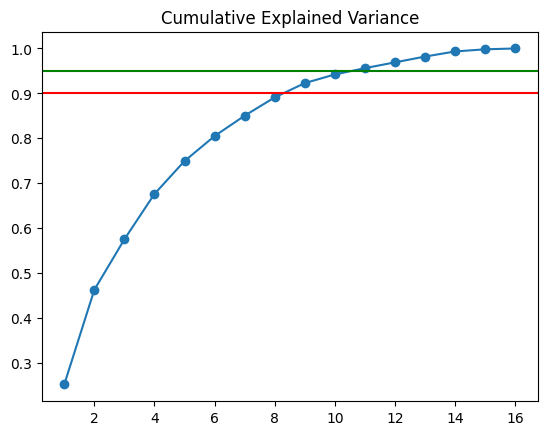

Components for 90% variance: 9


In [26]:
# 35. Cumulative variance
cum_variance = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o')
plt.axhline(y=0.90, color='r', linestyle='-')
plt.axhline(y=0.95, color='g', linestyle='-')
plt.title('Cumulative Explained Variance')
plt.show()
print(f"Components for 90% variance: {np.argmax(cum_variance >= 0.90) + 1}")

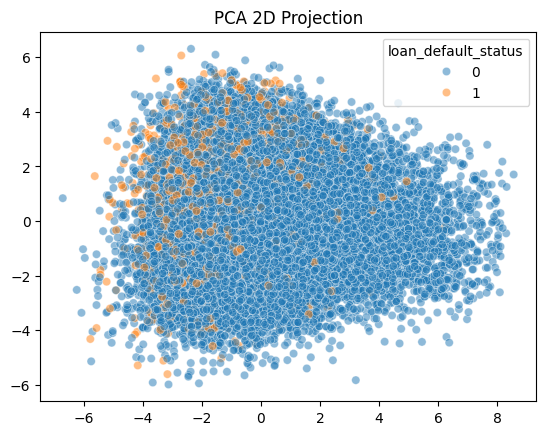

In [27]:
# 36. PCA 2D projection
X_pca_2 = PCA(n_components=2).fit_transform(X_scaled)
sns.scatterplot(x=X_pca_2[:, 0], y=X_pca_2[:, 1], hue=y_full, alpha=0.5)
plt.title('PCA 2D Projection')
plt.show()

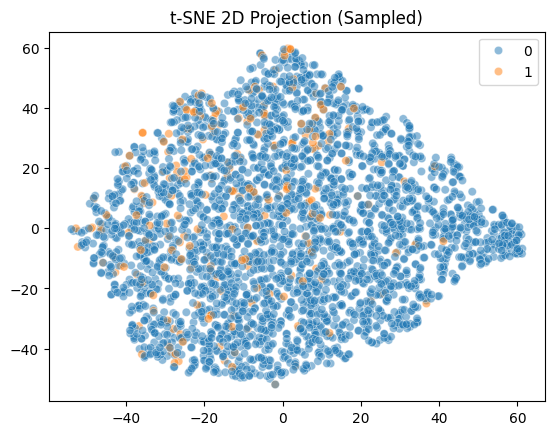

In [28]:
# 37. t-SNE 2D projection
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(X_scaled), min(3000, len(X_scaled)), replace=False)
X_tsne = TSNE(n_components=2, random_state=42).fit_transform(X_scaled[sample_idx])
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_full.iloc[sample_idx].values, alpha=0.5)
plt.title('t-SNE 2D Projection (Sampled)')
plt.show()

**Insight (38):** Both projections provide visual indications of non-linear structural separability between classes.

### Part G: Train/Test Split & SMOTE

In [29]:
# 39, 40, 41 - reuse the split fixed before target encoding (same seed, same stratification)
X_train, X_test = X_full.loc[train_idx, final_features], X_full.loc[test_idx, final_features]
y_train, y_test = y_full.loc[train_idx], y_full.loc[test_idx]
print("Train dist:\n", y_train.value_counts(normalize=True))
print("Test dist:\n", y_test.value_counts(normalize=True))

Train dist:
 loan_default_status
0    0.921333
1    0.078667
Name: proportion, dtype: float64
Test dist:
 loan_default_status
0    0.921333
1    0.078667
Name: proportion, dtype: float64


In [30]:
# 42, 43. Apply SMOTE
X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
print("Train dist after SMOTE:\n", y_train_smote.value_counts(normalize=True))

Train dist after SMOTE:
 loan_default_status
0    0.5
1    0.5
Name: proportion, dtype: float64


**Insight:** By augmenting the minority class, we equip upcoming predictive models with stronger signals without biasing the evaluation set.

### Part H: Save Outputs

In [31]:
os.makedirs(data_dir, exist_ok=True)
df_engineered.to_csv(os.path.join(data_dir, 'borrower_featured.csv'), index=False)

X_train.assign(loan_default_status=y_train).to_csv(os.path.join(data_dir, 'train.csv'), index=False)
X_test.assign(loan_default_status=y_test).to_csv(os.path.join(data_dir, 'test.csv'), index=False)
X_train_smote.assign(loan_default_status=y_train_smote).to_csv(os.path.join(data_dir, 'train_smote.csv'), index=False)

with open(os.path.join(data_dir, 'feature_columns.txt'), 'w') as f:
    for col in final_features:
        f.write(f"{col}\n")

**Summary:** Complete feature generation, subset optimization, class balancing, and artifact serialization achieved successfully.